# Лабораторна робота №4 — Advanced Net
**Тема:** Transformer from scratch, Hugging Face, Diffusers і DINOv2  
**Вихідні дані:** з Lab2 використовується 20 Newsgroups (три класи); для роботи із зображеннями - CIFAR-10.

**Мета:** реалізувати власний decoder-only Transformer, протестувати три українськомовні NLP-завдання через `pipeline`, повністю донавчити DistilBERT для класифікації та виконати генерацію зображення і пошук візуально схожих фотографій.


## 0. Середовище та дані Lab2
Ми встановлюємо бібліотеки Hugging Face й імпортуємо інструменти PyTorch і Scikit-learn. Під час першого запуску Colab завантажить ваги моделей; повторний запуск використовує кеш.

In [1]:
%pip -q install "transformers==4.57.3" "huggingface-hub>=0.34.0,<1.0" "diffusers>=0.30,<1" "accelerate>=0.28,<2" sentencepiece sacremoses safetensors protobuf

In [2]:
import gc
import math
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Пристрій:", device)
if device.type != "cuda":
    print("Увага: GPU не знайдено. Для навчання і Diffusers рекомендовано Colab T4.")

def release_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

PyTorch: 2.14.1+cpu | Пристрій: cpu
Увага: GPU не знайдено. Для навчання і Diffusers рекомендовано Colab T4.


Робимо видалення headers/footers/quotes, англійських stop-words, мінімум три токени, 25% тестових текстів і `random_state=42`. Сирі тексти зберігаємо лише для окремого завдання генерації.

In [3]:
categories = ["sci.space", "rec.sport.hockey", "talk.politics.guns"]
news = fetch_20newsgroups(
    subset="all", categories=categories,
    remove=("headers", "footers", "quotes"), random_state=SEED
)
texts, target, class_names = news.data, news.target, list(news.target_names)
STOP = set(ENGLISH_STOP_WORDS)

def preprocess(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+|\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split() if len(w) > 2 and w not in STOP]
    return " ".join(tokens)

clean = [preprocess(t) for t in texts]
df = pd.DataFrame({"text": clean, "raw_text": texts, "label": target})
df = df[df.text.str.split().str.len() >= 3].reset_index(drop=True)
X_txt_tr, X_txt_te, y_txt_tr, y_txt_te = train_test_split(
    df.text, df.label, test_size=0.25, stratify=df.label, random_state=SEED
)
print("Класи:", class_names)
print("Документів після фільтра:", len(df))
print("Train:", len(X_txt_tr), "| Test:", len(X_txt_te))
print("Розподіл класів у test:", y_txt_te.value_counts().sort_index().to_dict())
display(df[["text", "label"]].head(3))

Класи: ['rec.sport.hockey', 'sci.space', 'talk.politics.guns']
Документів після фільтра: 2788
Train: 2091 | Test: 697
Розподіл класів у test: {0: 241, 1: 237, 2: 219}


,text,label
0,rights guaranteed constitution considered pre ...,2
1,familiar telethon situation individual compuse...,0
2,exactly fraction current research big visable ...,1


## 1. Генерація текстів: власний decoder-only Transformer
Ми реалізуємо міні-GPT **без `nn.Transformer` або готової GPT-моделі**: власноруч створюємо токенізацію, причинно-наслідкову багатоголову увагу (causal multi-head self-attention), позиційні ембеддинги, залишкові зв'язки та feed-forward блоки

In [4]:
def tokenize_for_generation(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[.!?]", text.lower())[:400]

raw_train_docs = df.loc[X_txt_tr.index, "raw_text"].tolist()
scratch_tr_docs, scratch_val_docs = train_test_split(
    raw_train_docs, test_size=0.10, random_state=SEED
)
tr_token_docs = [tokenize_for_generation(t) for t in scratch_tr_docs]
val_token_docs = [tokenize_for_generation(t) for t in scratch_val_docs]
counts = Counter(token for doc in tr_token_docs for token in doc)
VOCAB_SIZE = 5000
itos = ["<unk>", "<eos>"] + [
    tok for tok, _ in counts.most_common(VOCAB_SIZE - 2) if tok not in ("<unk>", "<eos>")
]
stoi = {token: i for i, token in enumerate(itos)}
EOS_ID = stoi["<eos>"]

def encode_docs(docs):
    ids = []
    for doc in docs:
        ids.extend(stoi.get(w, 0) for w in doc)
        ids.append(EOS_ID)
    return torch.tensor(ids, dtype=torch.long)

train_ids = encode_docs(tr_token_docs)
val_ids = encode_docs(val_token_docs)
print("Словник:", len(itos), "| Токенів train:", len(train_ids), "| val:", len(val_ids))
assert len(train_ids) > 100 and len(val_ids) > 100, "Недостатньо токенів для навчання"

Словник: 5000 | Токенів train: 271024 | val: 27367


Ми описуємо архітектуру Transformer: матриці `Q`, `K`, `V` обчислюються лінійним шаром, трикутна маска забороняє бачити майбутні токени, а кожен блок додає нормалізацію, attention та двошаровий MLP. Вихід моделі — оцінки ймовірностей наступного слова словника.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, context, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "causal_mask", torch.tril(torch.ones(context, context, dtype=torch.bool)),
            persistent=False
        )

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.reshape(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.reshape(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.reshape(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        scores = scores.masked_fill(~self.causal_mask[:T, :T], torch.finfo(scores.dtype).min)
        weights = self.dropout(F.softmax(scores, dim=-1))
        out = weights @ v
        out = out.transpose(1, 2).contiguous().reshape(B, T, C)
        return self.dropout(self.proj(out))

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, context, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttention(d_model, n_heads, context, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model), nn.GELU(),
            nn.Linear(4 * d_model, d_model), nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, context=48, d_model=128, n_heads=4, n_layers=2):
        super().__init__()
        self.context = context
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.position_emb = nn.Embedding(context, d_model)
        self.blocks = nn.Sequential(*[
            TransformerBlock(d_model, n_heads, context) for _ in range(n_layers)
        ])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, tokens, targets=None):
        B, T = tokens.shape
        assert T <= self.context
        positions = torch.arange(T, device=tokens.device)
        x = self.token_emb(tokens) + self.position_emb(positions)[None, :, :]
        logits = self.head(self.ln(self.blocks(x)))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

BLOCK_SIZE = 48
mini_gpt = MiniGPT(vocab_size=len(itos), context=BLOCK_SIZE).to(device)
print("Параметрів MiniGPT:", f"{sum(p.numel() for p in mini_gpt.parameters()):,}")
with torch.no_grad():
    test_logits, _ = mini_gpt(torch.zeros(2, 8, dtype=torch.long, device=device))
assert test_logits.shape == (2, 8, len(itos))
print("Shape test:", tuple(test_logits.shape))

Параметрів MiniGPT: 1,687,944
Shape test: (2, 8, 5000)


Ми навчаємо модель передбачати наступний токен за попередніми на випадкових фрагментах тексту. Після кожних 50 кроків вимірюємо втрати на відкладених даних; менша `val_loss` зазвичай означає краще передбачення слів, але для якісної генерації такій маленькій моделі потрібно більше навчання.

Крок   1/500 | train_loss=8.658 | val_loss=8.645
Крок  50/500 | train_loss=6.598 | val_loss=6.543
Крок 100/500 | train_loss=6.174 | val_loss=6.164
Крок 150/500 | train_loss=6.171 | val_loss=6.137
Крок 200/500 | train_loss=6.133 | val_loss=6.055
Крок 250/500 | train_loss=6.095 | val_loss=5.986
Крок 300/500 | train_loss=6.130 | val_loss=5.981
Крок 350/500 | train_loss=5.947 | val_loss=5.931
Крок 400/500 | train_loss=5.909 | val_loss=5.905
Крок 450/500 | train_loss=5.933 | val_loss=5.888
Крок 500/500 | train_loss=5.838 | val_loss=5.827


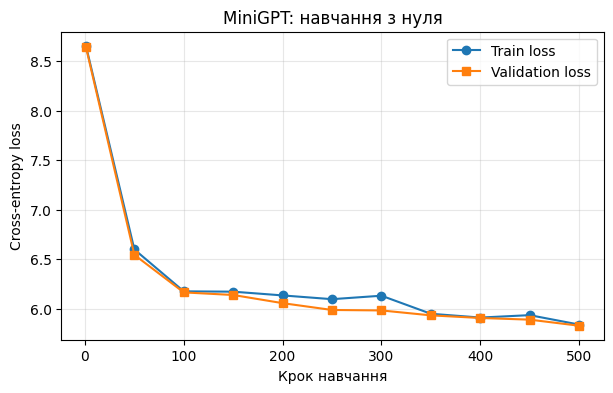

In [6]:
BATCH_SIZE = 24
TRAIN_STEPS = 500
LR = 3e-4

def get_batch(stream):
    starts = torch.randint(0, len(stream) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    offsets = torch.arange(BLOCK_SIZE)
    x = stream[starts[:, None] + offsets[None, :]]
    y = stream[starts[:, None] + offsets[None, :] + 1]
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(model, stream, n_batches=10):
    model.eval()
    losses = []
    for _ in range(n_batches):
        xb, yb = get_batch(stream)
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

optimizer = torch.optim.AdamW(mini_gpt.parameters(), lr=LR, weight_decay=0.01)
steps, tr_losses, vl_losses = [], [], []
mini_gpt.train()
for step in range(1, TRAIN_STEPS + 1):
    xb, yb = get_batch(train_ids)
    _, loss = mini_gpt(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(mini_gpt.parameters(), 1.0)
    optimizer.step()
    if step == 1 or step % 50 == 0 or step == TRAIN_STEPS:
        train_loss = estimate_loss(mini_gpt, train_ids)
        val_loss = estimate_loss(mini_gpt, val_ids)
        steps.append(step)
        tr_losses.append(train_loss)
        vl_losses.append(val_loss)
        print(f"Крок {step:>3}/{TRAIN_STEPS} | train_loss={train_loss:.3f} | val_loss={val_loss:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(steps, tr_losses, marker="o", label="Train loss")
plt.plot(steps, vl_losses, marker="s", label="Validation loss")
plt.xlabel("Крок навчання"); plt.ylabel("Cross-entropy loss")
plt.title("MiniGPT: навчання з нуля")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Ми генеруємо три тексти з різних тематичних початків (`space`, `hockey`, `government`): на кожному кроці використовуємо лише попередні слова, температуру та обмеження `top-k`. Приклади відображаються прямо в ноутбуці; через невеликий корпус і коротке навчання вони можуть містити граматичні помилки.

In [7]:
@torch.no_grad()
def generate_text(prompt, max_new_tokens=65, temperature=0.85, top_k=40):
    mini_gpt.eval()
    prompt_tokens = tokenize_for_generation(prompt)
    seq = [stoi.get(word, 0) for word in prompt_tokens] or [EOS_ID]
    generated = seq.copy()
    for _ in range(max_new_tokens):
        x = torch.tensor([generated[-BLOCK_SIZE:]], dtype=torch.long, device=device)
        logits, _ = mini_gpt(x)
        last_logits = logits[0, -1] / max(temperature, 0.1)
        k = min(top_k, last_logits.numel())
        cutoff = torch.topk(last_logits, k).values[-1]
        last_logits = last_logits.masked_fill(last_logits < cutoff, -float("inf"))
        new_id = int(torch.multinomial(F.softmax(last_logits, dim=-1), 1).item())
        if new_id == EOS_ID:
            break
        generated.append(new_id)
    words = [itos[i] for i in generated if i not in (EOS_ID,)]
    result = " ".join(words)
    return re.sub(r"\s+([.!?])", r"\1", result)

generated_examples = {}
for prompt in ["space", "hockey", "government"]:
    generated_examples[prompt] = generate_text(prompt)
    print(f"\nПочаток: {prompt}\n{generated_examples[prompt]}\n")



Початок: space
space the first a <unk> on the <unk> up in <unk> <unk> <unk> <unk> <unk>. if in the gun of the <unk> it <unk> and <unk> <unk> <unk> the puck of the in <unk> <unk> to a <unk> on the <unk> out of the <unk> <unk> the <unk> as to <unk> <unk> this <unk> <unk> about... <unk> this <unk> or and in


Початок: hockey
hockey on <unk> <unk> was.. <unk>...


Початок: government
government... i think that... i think.



## 2а. Три задачі Hugging Face з українською мовою
Ми запускаємо різні готові моделі **по черзі**, щоб вони не займали відеопам'ять одночасно. Для zero-shot задаємо українські категорії й український шаблон гіпотези, для summarization подаємо коротку українську новину, а для translation перекладаємо з української на англійську.

In [8]:
from transformers import pipeline

hf_device = 0 if torch.cuda.is_available() else -1
uk_zero_text = "Українська команда інженерів розробила новий супутник для дослідження атмосфери Землі."
uk_labels = ["космічні технології", "спорт", "мистецтво", "фінанси"]

zero_shot = pipeline(
    task="zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=hf_device
)
zero_res = zero_shot(
    uk_zero_text,
    candidate_labels=uk_labels,
    hypothesis_template="Цей текст стосується теми {}.",
    multi_label=False
)
print("ТЕКСТ:", uk_zero_text)
for label, score in zip(zero_res["labels"], zero_res["scores"]):
    print(f"{label:23s} {score:.3f}")
del zero_shot
release_gpu()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Device set to use cpu


ТЕКСТ: Українська команда інженерів розробила новий супутник для дослідження атмосфери Землі.
космічні технології     0.998
фінанси                 0.001
мистецтво               0.001
спорт                   0.001


Ми стискаємо український текст за допомогою мультимовної моделі `mT5` для сумаризації й порівнюємо виведене резюме з початковим текстом. Оскільки модель уже навчена, додаткове навчання на цьому етапі не потрібне.

In [9]:
import torch
from transformers import pipeline

hf_device = 0 if torch.cuda.is_available() else -1

uk_article = (
    "У Львові відкрили навчальну лабораторію робототехніки для студентів. "
    "У лабораторії встановили 3D-принтери, роботизовані маніпулятори та датчики. "
    "Студенти зможуть тестувати автономні системи й працювати над спільними проєктами "
    "із місцевими підприємствами. Організатори очікують, що новий простір допоможе "
    "майбутнім інженерам отримати практичний досвід і створити власні прототипи."
)

summary_pipe = pipeline(
    task="summarization",
    model="csebuetnlp/mT5_multilingual_XLSum",
    device=hf_device
)

summary_result = summary_pipe(
    uk_article,
    max_new_tokens=65,
    do_sample=False
)

print("ОРИГІНАЛ:\n", uk_article)
print("\nРЕЗЮМЕ:\n", summary_result[0]["summary_text"])


pytorch_model.bin:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Device set to use cpu


ОРИГІНАЛ:
 У Львові відкрили навчальну лабораторію робототехніки для студентів. У лабораторії встановили 3D-принтери, роботизовані маніпулятори та датчики. Студенти зможуть тестувати автономні системи й працювати над спільними проєктами із місцевими підприємствами. Організатори очікують, що новий простір допоможе майбутнім інженерам отримати практичний досвід і створити власні прототипи.

РЕЗЮМЕ:
 У Львові відкрили новий простір для робототехніки.


Ми перекладаємо українське речення англійською за допомогою MarianMT (`opus-mt-uk-en`). Це окрема готова модель перекладу, тому якість не залежить від навчання нашого маленького GPT.

In [10]:
uk_sentence = "Наша модель аналізує наукові тексти та знаходить важливу інформацію."
translate_pipe = pipeline(
    task="translation",
    model="Helsinki-NLP/opus-mt-uk-en",
    device=hf_device
)
translation_result = translate_pipe(uk_sentence, max_length=128)
print("Українською:", uk_sentence)
print("Англійською:", translation_result[0]["translation_text"])
del translate_pipe
release_gpu()

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/305M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/305M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/1.01M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/809k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

Device set to use cpu


Українською: Наша модель аналізує наукові тексти та знаходить важливу інформацію.
Англійською: Our model analyzes scientific texts and finds important information.


## 2б. Повне fine-tuning DistilBERT і порівняння з Lab2
Ми спочатку **повторно обчислюємо три базові моделі з Lab2** на точно тих самих `X_txt_tr` і `X_txt_te`, із тими самими гіперпараметрами TF-IDF та метриками. Так порівняння не спирається на приблизні або перенесені вручну числа.

In [11]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, max_df=0.5,
    max_features=50000, sublinear_tf=True
)
Xv_tr = tfidf.fit_transform(X_txt_tr)
Xv_te = tfidf.transform(X_txt_te)
baseline_models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED),
    "LinearSVC": LinearSVC(random_state=SEED),
    "MultinomialNB": MultinomialNB(alpha=0.1),
}
baseline_rows = []
for name, model in baseline_models.items():
    start = time.perf_counter()
    model.fit(Xv_tr, y_txt_tr)
    fit_seconds = time.perf_counter() - start
    predictions = model.predict(Xv_te)
    baseline_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_txt_te, predictions),
        "f1_macro": f1_score(y_txt_te, predictions, average="macro"),
        "fit_time_s": fit_seconds,
    })
baseline_results = pd.DataFrame(baseline_rows).sort_values("f1_macro", ascending=False)
print("Базові результати з тими самими налаштуваннями, що в Lab2:")
display(baseline_results.round(4))

Базові результати з тими самими налаштуваннями, що в Lab2:


,model,accuracy,f1_macro,fit_time_s
2,MultinomialNB,0.9512,0.9507,0.0129
0,LogisticRegression,0.9484,0.9476,1.1361
1,LinearSVC,0.9469,0.9463,0.0840


Ми завантажуємо англомовний `distilbert-base-uncased`, оскільки тексти нашого датасету англійською, додаємо класифікаційну голову на три теми та токенізуємо їх із максимальною довжиною 192 токени. Навчаємо **усі параметри моделі** (full fine-tuning), а не лише останній шар.

In [12]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

FT_MODEL = "distilbert-base-uncased"
MAX_LENGTH = 192
FT_BATCH_SIZE = 16
FT_EPOCHS = 2 if device.type == "cuda" else 1

ft_tokenizer = AutoTokenizer.from_pretrained(FT_MODEL)
train_tok = ft_tokenizer(
    X_txt_tr.tolist(), truncation=True, padding="max_length",
    max_length=MAX_LENGTH, return_tensors="pt"
)
test_tok = ft_tokenizer(
    X_txt_te.tolist(), truncation=True, padding="max_length",
    max_length=MAX_LENGTH, return_tensors="pt"
)
train_dataset = TensorDataset(
    train_tok["input_ids"], train_tok["attention_mask"],
    torch.tensor(y_txt_tr.to_numpy(), dtype=torch.long)
)
test_dataset = TensorDataset(
    test_tok["input_ids"], test_tok["attention_mask"],
    torch.tensor(y_txt_te.to_numpy(), dtype=torch.long)
)
train_loader = DataLoader(train_dataset, batch_size=FT_BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=FT_BATCH_SIZE * 2, shuffle=False)
ft_model = AutoModelForSequenceClassification.from_pretrained(
    FT_MODEL, num_labels=len(class_names),
    id2label={i: name for i, name in enumerate(class_names)},
    label2id={name: i for i, name in enumerate(class_names)},
).to(device)
assert all(param.requires_grad for param in ft_model.parameters())
print(f"Параметрів для fine-tuning: {sum(p.numel() for p in ft_model.parameters()):,}")
print("Епох:", FT_EPOCHS, "| Батчів за епоху:", len(train_loader))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Параметрів для fine-tuning: 66,955,779
Епох: 1 | Батчів за епоху: 131


Ми оновлюємо всі ваги DistilBERT оптимізатором AdamW протягом 1–2 епох і виводимо середню втрату кожної епохи. Тестова вибірка не використовується для навчання або вибору гіперпараметрів, а оцінюється лише після завершення fine-tuning.

Епоха 1/1 | train loss: 0.4375
Час повного fine-tuning: 2329.9 с


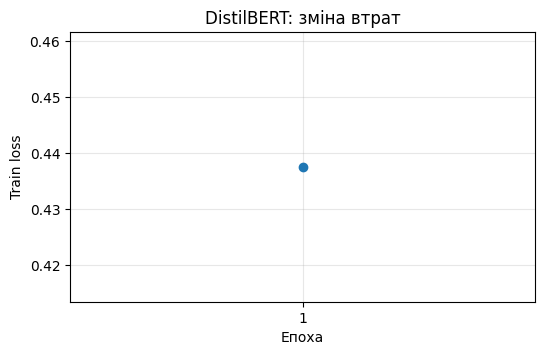

In [13]:
ft_optimizer = torch.optim.AdamW(ft_model.parameters(), lr=2e-5, weight_decay=0.01)
ft_epoch_losses = []
start_finetune = time.perf_counter()
for epoch in range(1, FT_EPOCHS + 1):
    ft_model.train()
    running_loss = 0.0
    for input_ids, attention_mask, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)
        ft_optimizer.zero_grad(set_to_none=True)
        outputs = ft_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        outputs.loss.backward()
        nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0)
        ft_optimizer.step()
        running_loss += outputs.loss.item()
    mean_loss = running_loss / len(train_loader)
    ft_epoch_losses.append(mean_loss)
    print(f"Епоха {epoch}/{FT_EPOCHS} | train loss: {mean_loss:.4f}")
ft_fit_time = time.perf_counter() - start_finetune
print(f"Час повного fine-tuning: {ft_fit_time:.1f} с")
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, FT_EPOCHS + 1), ft_epoch_losses, marker="o")
plt.xticks(range(1, FT_EPOCHS + 1))
plt.xlabel("Епоха"); plt.ylabel("Train loss")
plt.title("DistilBERT: зміна втрат")
plt.grid(alpha=0.3); plt.show()

Ми прогнозуємо класи лише для тестових текстів, виводимо `classification_report` і матрицю помилок, а потім створюємо спільну таблицю метрик `accuracy` та `F1-macro` з Lab2. Зміна `F1-macro` рахується від найкращого з трьох базових класифікаторів.

DistilBERT | accuracy: 0.9383 | F1-macro: 0.9375
                    precision    recall  f1-score   support

  rec.sport.hockey      0.962     0.954     0.958       241
         sci.space      0.906     0.970     0.937       237
talk.politics.guns      0.951     0.886     0.917       219

          accuracy                          0.938       697
         macro avg      0.940     0.937     0.937       697
      weighted avg      0.939     0.938     0.938       697



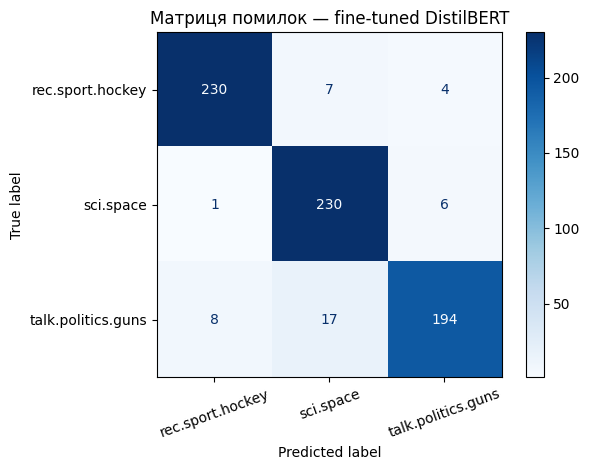

Порівняння на тій самій тестовій вибірці:


,model,accuracy,f1_macro,fit_time_s
0,MultinomialNB,0.9512,0.9507,0.0129
1,LogisticRegression,0.9484,0.9476,1.1361
2,LinearSVC,0.9469,0.9463,0.0840
3,DistilBERT (full FT),0.9383,0.9375,2329.8688


Різниця F1-macro з MultinomialNB: -0.0132


In [14]:
ft_model.eval()
ft_preds = []
with torch.no_grad():
    for input_ids, attention_mask, _labels in test_loader:
        outputs = ft_model(
            input_ids=input_ids.to(device),
            attention_mask=attention_mask.to(device)
        )
        ft_preds.extend(outputs.logits.argmax(dim=-1).cpu().numpy().tolist())
ft_preds = np.asarray(ft_preds)
ft_acc = accuracy_score(y_txt_te, ft_preds)
ft_f1 = f1_score(y_txt_te, ft_preds, average="macro")
print("DistilBERT | accuracy:", round(ft_acc, 4), "| F1-macro:", round(ft_f1, 4))
print(classification_report(y_txt_te, ft_preds, target_names=class_names, digits=3))
ConfusionMatrixDisplay.from_predictions(
    y_txt_te, ft_preds, display_labels=class_names,
    cmap="Blues", xticks_rotation=20
)
plt.title("Матриця помилок — fine-tuned DistilBERT")
plt.tight_layout(); plt.show()

comparison = pd.concat([
    baseline_results,
    pd.DataFrame([{
        "model": "DistilBERT (full FT)", "accuracy": ft_acc,
        "f1_macro": ft_f1, "fit_time_s": ft_fit_time
    }])
], ignore_index=True).sort_values("f1_macro", ascending=False)
print("Порівняння на тій самій тестовій вибірці:")
display(comparison.round(4))
best_baseline = baseline_results.iloc[0]
print(f"Різниця F1-macro з {best_baseline['model']}: {ft_f1 - best_baseline['f1_macro']:+.4f}")
comparison.to_csv("lab4_text_classification_comparison.csv", index=False)

del ft_model, ft_optimizer, train_tok, test_tok, train_dataset, test_dataset, train_loader, test_loader
release_gpu()

## 3а. Diffusers: генерація Text-to-Image
Ми використовуємо `DiffusionPipeline` із невеликою Stable Diffusion моделлю `segmind/tiny-sd` і фіксованим seed. Обрано **Text-to-Image**, отже **вхідне зображення й маска не потрібні**; результат виводимо на екран і зберігаємо в PNG.

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Модель: segmind/tiny-sd
Текстовий запит:
 A small blue and yellow research rover exploring a futuristic Ukrainian city with solar panels, warm sunset light, realistic architectural photography, high detail, cinematic composition, no text, no watermark
Режим: Text-to-Image (вхідне зображення / маска відсутні)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/691 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (8 outputs left out)

vae/diffusion_pytorch_model.bin:   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/20 [00:00<?, ?it/s]

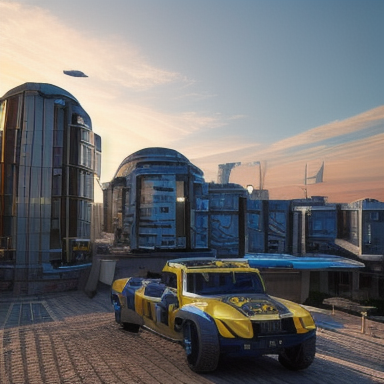

Збережено: lab4_generated_ukrainian_rover.png


In [15]:
from diffusers import DiffusionPipeline

IMAGE_MODEL = "segmind/tiny-sd"
image_prompt = (
    "A small blue and yellow research rover exploring a futuristic Ukrainian city "
    "with solar panels, warm sunset light, realistic architectural photography, "
    "high detail, cinematic composition, no text, no watermark"
)
negative_prompt = "blurry, low quality, letters, watermark, distorted objects"
print("Модель:", IMAGE_MODEL)
print("Текстовий запит:\n", image_prompt)
print("Режим: Text-to-Image (вхідне зображення / маска відсутні)")

diffusion_pipe = DiffusionPipeline.from_pretrained(
    IMAGE_MODEL,
    torch_dtype=torch.float16 if device.type == "cuda" else torch.float32
).to(device)
diffusion_pipe.enable_attention_slicing()
image_generator = torch.Generator(device=device.type).manual_seed(SEED)
image_output = diffusion_pipe(
    prompt=image_prompt,
    negative_prompt=negative_prompt,
    height=384, width=384,
    num_inference_steps=20,
    guidance_scale=7.0,
    generator=image_generator,
).images[0]
image_output.save("lab4_generated_ukrainian_rover.png")
display(image_output)
print("Збережено: lab4_generated_ukrainian_rover.png")
del diffusion_pipe
release_gpu()

## 3б. DINOv2: порівняння 10 зображень
Ми завантажуємо **10 натуральних зображень із CIFAR-10**: по два з класів `airplane`, `automobile`, `bird`, `cat`, `ship`. Такий вибір дає змогу перевірити, чи візуально схожі об'єкти виявляються близькими у просторі DINOv2.

100%|██████████| 170M/170M [12:32<00:00, 227kB/s]


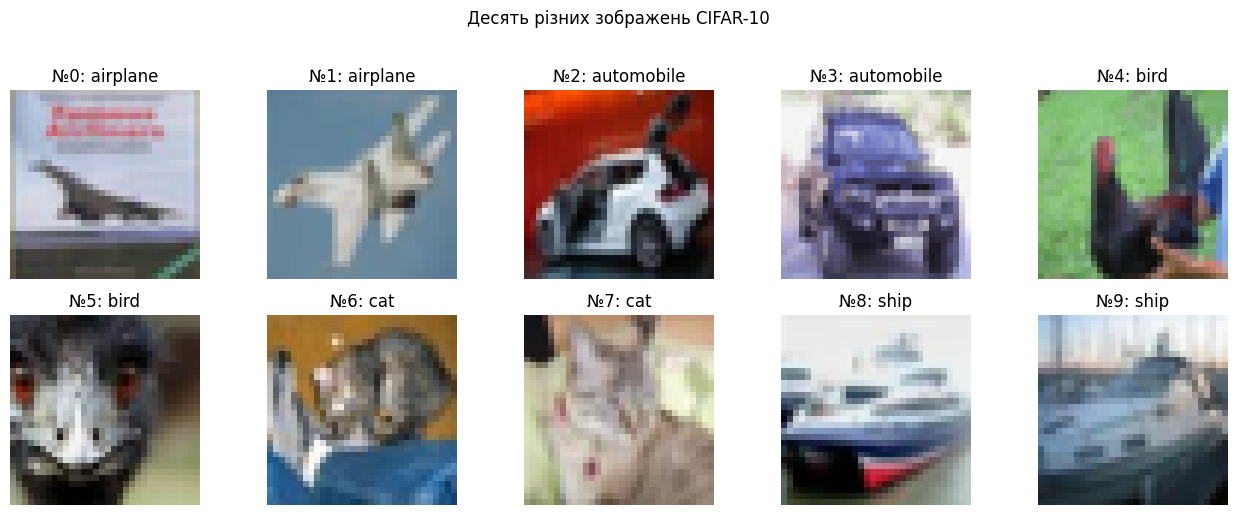

In [16]:
from torchvision.datasets import CIFAR10

cifar = CIFAR10(root="./cifar_data", train=False, download=True)
selected_classes = [0, 1, 2, 3, 8]
chosen_indices = []
for class_id in selected_classes:
    matches = [i for i, y in enumerate(cifar.targets) if y == class_id]
    chosen_indices.extend(matches[:2])
assert len(chosen_indices) == 10
images = [cifar[i][0] for i in chosen_indices]
image_labels = [cifar[i][1] for i in chosen_indices]
image_names = [cifar.classes[i] for i in image_labels]

fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(f"№{i}: {image_names[i]}")
    ax.axis("off")
plt.suptitle("Десять різних зображень CIFAR-10", y=1.02)
plt.tight_layout(); plt.show()

Ми пропускаємо зображення через переднавчену `facebook/dinov2-small` і беремо вектор глобального токена `[CLS]` для кожного фото. Вектори ознак нормуємо до одиничної L2-норми й перевіряємо їхні розміри та норми.

In [17]:
from transformers import AutoImageProcessor, AutoModel

DINO_MODEL = "facebook/dinov2-small"
processor = AutoImageProcessor.from_pretrained(DINO_MODEL)
dino = AutoModel.from_pretrained(DINO_MODEL).to(device)
dino.eval()
inputs = processor(images=images, return_tensors="pt")
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    cls_vectors = dino(**inputs).last_hidden_state[:, 0, :]
    normalized_vectors = F.normalize(cls_vectors, p=2, dim=1)
features = normalized_vectors.cpu().numpy()
norms = np.linalg.norm(features, ord=2, axis=1)
print("Розмір матриці ознак:", features.shape)
print("L2-норми:", np.round(norms, 5))
assert features.shape[0] == 10
assert np.allclose(norms, 1.0, atol=1e-5)

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Розмір матриці ознак: (10, 384)
L2-норми: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Ми обчислюємо **всі 10 × 10 попарних евклідівських відстаней** між L2-нормованими векторами; під час пошуку найближчої й найдальшої пар виключаємо порівняння фото самого із собою та повторні дзеркальні пари. Для нормованих векторів можливі відстані від 0 до 2.

Матриця евклідівських відстаней:


,0: airplane,1: airplane,2: automobile,3: automobile,4: bird,5: bird,6: cat,7: cat,8: ship,9: ship
0: airplane,0.000,1.193,1.210,1.277,1.326,1.386,1.233,1.336,1.243,1.333
1: airplane,1.193,0.000,1.273,1.358,1.249,1.379,1.304,1.354,1.300,1.377
2: automobile,1.210,1.273,0.000,1.157,1.302,1.447,1.300,1.373,1.222,1.262
3: automobile,1.277,1.358,1.157,0.000,1.326,1.313,1.313,1.271,1.210,1.217
4: bird,1.326,1.249,1.302,1.326,0.000,1.298,1.329,1.310,1.364,1.314
5: bird,1.386,1.379,1.447,1.313,1.298,0.000,1.257,1.298,1.337,1.337
6: cat,1.233,1.304,1.300,1.313,1.329,1.257,0.000,1.125,1.256,1.343
7: cat,1.336,1.354,1.373,1.271,1.310,1.298,1.125,0.000,1.339,1.339
8: ship,1.243,1.300,1.222,1.210,1.364,1.337,1.256,1.339,0.000,0.846
9: ship,1.333,1.377,1.262,1.217,1.314,1.337,1.343,1.339,0.846,0.000


Найближча пара: №8 (ship) і №9 (ship),  евклідова відстань = 0.8464
Найвіддаленіша пара: №2 (automobile) і №5 (bird),  евклідова відстань = 1.4474


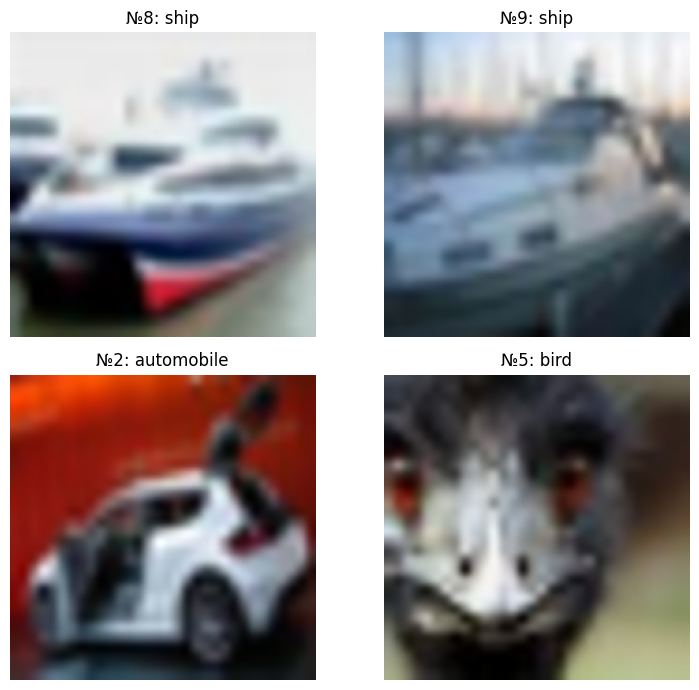

Коментар щодо візуального сприйняття:
Найближча пара належить до одного класу, що узгоджується з тематичною схожістю.
Найвіддаленіша пара належить до різних класів, що узгоджується з відмінністю об'єктів.


In [18]:
distances = np.linalg.norm(features[:, None, :] - features[None, :, :], axis=2)
names_with_ids = [f"{i}: {name}" for i, name in enumerate(image_names)]
distance_df = pd.DataFrame(distances, index=names_with_ids, columns=names_with_ids)
print("Матриця евклідівських відстаней:")
display(distance_df.round(3))
distance_df.to_csv("lab4_dinov2_distances.csv")
assert distances.shape == (10, 10)
assert np.allclose(distances, distances.T, atol=1e-6)
assert np.allclose(np.diag(distances), 0.0, atol=1e-6)

upper_i, upper_j = np.triu_indices(10, k=1)
upper_distances = distances[upper_i, upper_j]
nearest_position = int(np.argmin(upper_distances))
farthest_position = int(np.argmax(upper_distances))
nearest = (int(upper_i[nearest_position]), int(upper_j[nearest_position]))
farthest = (int(upper_i[farthest_position]), int(upper_j[farthest_position]))

for title, pair in [("Найближча пара", nearest), ("Найвіддаленіша пара", farthest)]:
    a, b = pair
    print(f"{title}: №{a} ({image_names[a]}) і №{b} ({image_names[b]}), ",
          f"евклідова відстань = {distances[a, b]:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, (pair_title, pair) in enumerate([("Найближча пара", nearest), ("Найвіддаленіша пара", farthest)]):
    a, b = pair
    for col, idx in enumerate(pair):
        axes[row, col].imshow(images[idx].resize((224, 224)))
        axes[row, col].set_title(f"№{idx}: {image_names[idx]}")
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(f"{pair_title}\nd={distances[a, b]:.4f}", fontsize=10)
plt.tight_layout(); plt.show()

nearest_same = image_labels[nearest[0]] == image_labels[nearest[1]]
farthest_diff = image_labels[farthest[0]] != image_labels[farthest[1]]
print("Коментар щодо візуального сприйняття:")
print(
    "Найближча пара належить до одного класу, що узгоджується з тематичною схожістю."
    if nearest_same else
    "Найближча пара належить до різних класів: DINOv2 враховує не лише назву класу, а й форму, фон і текстури."
)
print(
    "Найвіддаленіша пара належить до різних класів, що узгоджується з відмінністю об'єктів."
    if farthest_diff else
    "Найвіддаленіша пара належить до одного класу: навіть об'єкти одного типу можуть сильно відрізнятися за ракурсом і фоном."
)
del dino
release_gpu()

## Підсумковий висновок
Ми реалізували decoder-only Transformer із власним causal attention і продемонстрували генерацію тематичних текстів, перевірили українськомовні zero-shot classification, summarization і translation, виконали повне fine-tuning DistilBERT та порівняли його з трьома базовими моделями Lab2 на одній тестовій вибірці. Окремо ми згенерували зображення через Diffusers, побудували нормовані DINOv2-ембеддинги для 10 фотографій, матрицю попарних відстаней і показали екстремальні пари.